# 1 · A first model: Jupiter as a single polytrope

**Covered topics:** how to create a planet, give it a pressure–density relation, let PyToF find the hydrostatic equilibrium shape, read off the gravitational moments $J_{2n}$, and how to judge whether the numbers can be trusted.

This is the first of five tutorial notebooks:

| notebook | topic |
|---|---|
| **1 · first model** (this one) | create a planet, relax it, read the results, accuracy estimates |
| 2 · plotting | profiles, 2D shape, figure functions, comparing models |
| 3 · your own planet | physical parameters, density profiles, atmospheres, density jumps |
| 4 · beyond the Js | moment of inertia, Love numbers, differential rotation |
| 5 · numerics guide | order, grid size, binning, tolerances, warnings, debugging |

The theory behind PyToF is described in Appendix A of Morf et al. (2024), [doi:10.1051/0004-6361/202450698](https://doi.org/10.1051/0004-6361/202450698).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from PyToF import ToF
from tutorial_utils import Bessel  # literature reference values, see below

plt.rcParams["figure.figsize"] = (5.2, 3.9)  # smaller default figures

`ToF` is the one class you need. Everything (options, results and methods) lives on its instances. Options are passed as keyword arguments and stored in `X.opts`. Misspelled names raise an error. A complete list with defaults and descriptions can be generated directly from the code:

In [2]:
from IPython.display import Markdown
from PyToF.options import Options

Markdown(Options.describe())

| group | option | default | description |
|---|---|---|---|
| numerics | `N` | `1024` | Number of level surfaces, `i.e`. grid points: the nested surfaces of constant density into which the planet is divided, each labelled by its mean radius (`ToF.li`). |
| numerics | `n_bin` | `-1` | Number of bins for the figure functions; -1 or N means no binning, positive values smaller than N are faster but less accurate. |
| numerics | `order` | `4` | Theory of Figures order: 4, 7 or 10. Higher orders are slower and more accurate. |
| numerics | `use_simpson` | `True` | PyToF uses Simpson's rule (otherwise the trapezoid rule) for internal integral calculations if True. PyToF falls back to the trapezoid rule on its own if Simpson's rule becomes unstable, see `ToF.simpson_in_use`. |
| numerics | `dJ_tol` | `1e-10` | Relative tolerance of the gravitational moments to quantify convergence. |
| numerics | `drot_tol` | `1e-10` | Relative tolerance of the rotational parameter to quantify convergence. |
| numerics | `drho_tol` | `1e-10` | Relative tolerance of the densities to quantify convergence. |
| numerics | `max_iter_relax_shape` | `100` | Maximum number of iterations of `relax_to_shape()`. One iteration is one full pass of the Theory of Figures algorithm. |
| numerics | `max_iter_relax_barotrope` | `100` | Maximum number of iterations of `relax_to_barotrope()`. Each iteration includes up to two passes of the Theory of Figures algorithm and up to `max_iter_density_update` density updates. Must be an integer >= 2. |
| numerics | `max_iter_relax_density` | `100` | Maximum number of iterations of `relax_to_density()`. Each iteration includes up to two passes of the Theory of Figures algorithm and up to `max_iter_density_update` density updates. Must be an integer >= 2. |
| numerics | `max_iter_density_update` | `100` | Maximum number of iterations of the inner density update that runs once per iteration of `relax_to_barotrope()` and `relax_to_density()`. It repeats the update of the densities (relevant if a barotrope or an atmosphere model are supplied) until they change by less than `drho_tol`. Must be an integer >= 2. |
| output | `verbosity` | `0` | How much PyToF prints; warnings are always issued. 0: quiet; 1: one summary line per iteration; 2: also timings, the atmosphere transition and the boundary conditions of the Love number calculation; 3: also one line per iteration and every renormalization of radius and mass. |
| output | `debug_plot` | `False` | Save debug plots at every iteration (very slow). |
| planet | `G` | `6.673848e-11` | Gravitational constant in SI units. |
| planet | `M_phys` | `1.8982532431065258e+27` | Mass of the planet in SI units (Jupiter by default). |
| planet | `R_phys` | `[71492000, 'equatorial']` | Physical radius in SI units and its kind: [value, 'equatorial' \| 'mean' \| 'polar'] (Jupiter by default). |
| planet | `R_ref` | `None` | Reference radius for the definition of the Js in SI units; defaults to the value in `R_phys`. |
| planet | `Period` | `35729.699778131784` | Rotation period in SI units (Jupiter by default). |
| planet | `P0` | `0` | Surface pressure in SI units. |
| planet | `alphas` | `array of length 12` | Barotropic differential rotation parameters in m^2 s^-2 (typically ~1e5; much smaller values have no visible effect). |
| model | `baro_param` | `None` | Parameters of the barotrope set via `set_barotrope()`: the barotrope is called as f(P, `baro_param`). Any object, `e.g`. a number or a list. |
| model | `use_atmosphere` | `False` | Use an atmospheric model for the outermost densities. |
| model | `atmosphere` | `None` | Function atmosphere(`mean_level_surface`, pressure) returning the density of the atmospheric model. |
| model | `atmosphere_until` | `None` | Pressure in SI units at which the atmospheric model may end earliest. |
| model | `H` | `0.0` | WORK IN PROGRESS |

## Barotropic models for planetary interiors

A common assumption found in planetary interior modelling is that of a barotropic interior: the density $\rho$ depends only on the pressure $P$, namely $\rho = \rho(P)$. 

We now use the simplest model, a so-called polytrope of index 1, given by $\rho = \sqrt{P/K}$. It is also the model used in Wisdom & Hubbard (2016, [doi:10.1016/j.icarus.2015.12.030](https://doi.org/10.1016/j.icarus.2015.12.030)). This model is useful in particular because it has an exact (Bessel-function) solution that we can use as a comparison. 

For a single polytrope describing a planet with mass $M$ and radius $R$, the constant $K$ is not a free parameter. It is rescaled iteratively to reproduce the given mass $M$ by PyToF.

A barotropic function (such as the above polytrope example) is implemented as a function `f(P, param)` in PyToF. The values you put in the option `baro_param` arrive as `param`. We model Jupiter as an example and hence have to supply no further values, as Jupiter corresponds to the default values of PyToF: Jupiter's mass, equatorial radius and rotation period, `N = 1024` level surfaces and Theory of Figures `order = 4` (see the table above). `baro_param` can be any Python object: a number for a single parameter, a list for several.

In [3]:
X = ToF()

print('Mass   [kg]', X.opts['M_phys'])
print('Radius [m] ', X.opts['R_phys'])
print('Period [s] ', X.opts['Period'])

def barotrope(P, K):
    return (P / K) ** 0.5
    
X.opts["baro_param"] = 1  # sets K=1, arbitrary for a single polytrope
X.set_barotrope(barotrope)

Mass   [kg] 1.8982532431065258e+27
Radius [m]  [71492000, 'equatorial']
Period [s]  35729.699778131784


## Relaxing to equilibrium

`relax_to_barotrope()` alternates between using the Theory of Figures algorithm (which computes the shape of the level surfaces for given densities and rotation, as an expansion in Legendre polynomials; the `order` is the order of this expansion in the rotation parameter) and updating pressure and densities according to the supplied barotrope function, until nothing changes any more. It returns the number of iterations:

In [4]:
n_iterations = X.relax_to_barotrope()
print("iterations:", n_iterations)

iterations: 17


**Convergence** means that between two iterations the gravitational moments, the densities, and the rotational parameter $m = \omega^2 l_\mathrm{max}^3 / (GM)$ all changed by less than the relative tolerances supplied via the options. Note that $\omega = 2\pi/P_\mathrm{rot}$.

Here $l_\mathrm{max}$ refers to the largest level surface of the model. PyToF divides the planet into `N` nested level surfaces (surfaces of constant density, pressure and potential), ordered from the outermost inwards. Each level surface is labelled by its mean radius $l$, the radius of the sphere that has the same volume as the surface encloses. The $N$ values $l_i$ are stored in `X.li`, with `X.li[0]` the outermost one. A rotating planet is flattened, so a level surface is not a sphere: its equatorial radius is larger and its polar radius smaller than $l$. The mean radius of the outermost level surface is written $l_\mathrm{max}$ (`X.li[0]`) and is also called $R_\mathrm{m}$; both names mean the same thing, $l_\mathrm{max} = R_\mathrm{m}$.

If the iteration limit is reached first, PyToF issues a `ConvergenceWarning` (an ordinary Python warning, see notebook 5 for how to silence or escalate it). `reset()` throws away all results and starts over from the initial state, so we can repeat the calculation with a limit that is too small:

In [5]:
X.opts["max_iter_relax_barotrope"] = n_iterations - 1
X.reset()
X.relax_to_barotrope()  # warns

X.opts["max_iter_relax_barotrope"] = 100  # back to normal

/tmp/ipykernel_17927/1581430815.py:3: ConvergenceWarning: drot = 4e-12 < 1e-10, dJ = 9e-10 > 1e-10, drho = 4e-12 < 1e-10 after max_iter_relax_barotrope = 16 iterations.
  X.relax_to_barotrope()  # warns


The option `verbosity` controls how chatty PyToF is: 0 is silent (warnings are always shown), 1 prints one summary line per `relax_to_*` call (iterations and final convergence measures), 2 adds timings and details such as the atmosphere transition, 3 prints one line per iteration.

In [6]:
X.opts["verbosity"] = 2
X.reset()
X.relax_to_barotrope()
X.opts["verbosity"] = 0

Relaxing to barotrope finished after 17 iterations: drot = 1.9e-13, dJ = 4.7e-11, drho = 1.9e-13.
Relaxing to barotrope done in 9.96e-02 seconds.


## Reading the results

The total potential $U$ of a planet consists of a centrifugal part (due to the co-rotating reference frame) and a gravitational part. We write $U_\mathrm{int}$ for positions inside and $U_\mathrm{ext}$ for positions outside of the planet. If the planet is north-south symmetric and rotationally symmetric, the gravitational part of $U_\mathrm{ext}$ can be written as

$$U_\mathrm{ext}(\vec{r}) = \frac{GM}{r}\left(1 - \sum_{n=1}^{\infty} \left(\frac{a}{r}\right)^{2n} J_{2n}\, P_{2n}(\cos\vartheta)\right),$$

with $G$ the gravitational constant, $M$ the mass of the planet, $a$ an arbitrary normalization constant that is usually chosen as the equatorial radius, $r$ and $\vartheta$ the radial coordinate and the colatitude, and $P_{2n}$ the Legendre polynomials. The so-called gravitational moments $J_{2n}$ are directly linked to the internal density distribution $\rho$:

$$J_{2n} = -\frac{1}{M a^{2n}} \int \rho(r,\vartheta)\, r^{2n} P_{2n}(\cos\vartheta)\, \mathrm{d}^3 r.$$

If $J_{2n} = 0$ for all $n \geq 1$, we recover the potential of a point mass (outside of the planet this holds for every spherically symmetric body). For $n = 0$ the integral gives $J_0 = -M/M = -1$, so the leading term of the potential is the $n=0$ term of the same series, $U_\mathrm{ext} = -\frac{GM}{r}\sum_{n=0}^{\infty} (a/r)^{2n} J_{2n} P_{2n}(\cos\vartheta)$.

In PyToF the normalization constant $a$ is the option `R_ref`. By default it is the radius given in `R_phys`, here Jupiter's equatorial radius, which Wisdom & Hubbard also use (see notebook 3). The moments are stored in `X.Js`: `X.Js[n]` is $J_{2n}$, and `X.Js[0]` is $J_0 = -1$ as just derived.

> **Sign convention.** The potential is positive ($U = GM/r$ for a point mass) and grows towards the centre of the planet. The array `X.U` (the potential on the level surfaces, see notebook 4) uses the same convention, so that hydrostatic equilibrium reads $\mathrm{d}P = \rho\,\mathrm{d}U$ and the gravitational acceleration is $g = -\mathrm{d}U/\mathrm{d}l$.

The equatorial radius divided by $R_\mathrm{m} = l_\mathrm{max}$, the mean radius of the outermost level surface (see above), is in `X.R_eq_to_R_m`. It measures how flattened the planet is.

We compare with the Bessel solution of Wisdom & Hubbard (2016), stored in `Bessel` ($R_\mathrm{eq}/R_\mathrm{m}$, $J_2$, $J_4$, …, $J_{20}$) in the file `accuracy/references.py`:

In [7]:
print(f"{'':12s}{'PyToF':>14s}{'W&H 2016':>14s}{'rel. diff.':>12s}")
print(f"{'Req/Rm':12s}{X.R_eq_to_R_m:14.6f}{Bessel[0]:14.6f}{abs(X.R_eq_to_R_m / Bessel[0] - 1):12.1e}")
for n in range(1, 5):
    print(f"{'J_' + str(2 * n):12s}{X.Js[n]:14.6e}{Bessel[n]:14.6e}{abs(X.Js[n] / Bessel[n] - 1):12.1e}")

                     PyToF      W&H 2016  rel. diff.
Req/Rm            1.022476      1.022875     3.9e-04
J_2           1.398844e-02  1.398851e-02     5.1e-06
J_4          -5.319627e-04 -5.318281e-04     2.5e-04
J_6           2.985996e-05  3.011832e-05     8.6e-03
J_8          -2.336280e-06 -2.132116e-06     9.6e-02


The errors grow quickly for the higher moments. This is expected for a 4th order Theory of Figures as it is based on an expansion that is cut after the 4th order terms, which limits the accuracy of $J_6$ and $J_8$ no matter how fine the grid is. The next section shows how to reduce this.

> **A note on $R_\mathrm{eq}/R_\mathrm{m}$.** The ratio differs from the Bessel value by about $4\times10^{-4}$ for all grid sizes and orders. It is not yet clear whether this is a different definition of the "mean" radius or a real discrepancy.

## Order and number of level surfaces

Two knobs control the accuracy: the number `N` of level surfaces (how finely the planet is divided, see above) and the Theory of Figures `order` (4, 7 or 10). Let us look at the error of $J_2$, $J_4$, $J_6$ and $J_8$ for several of each. The small helper `jupiter()` from `tutorial_utils.py` builds the model above in one line:

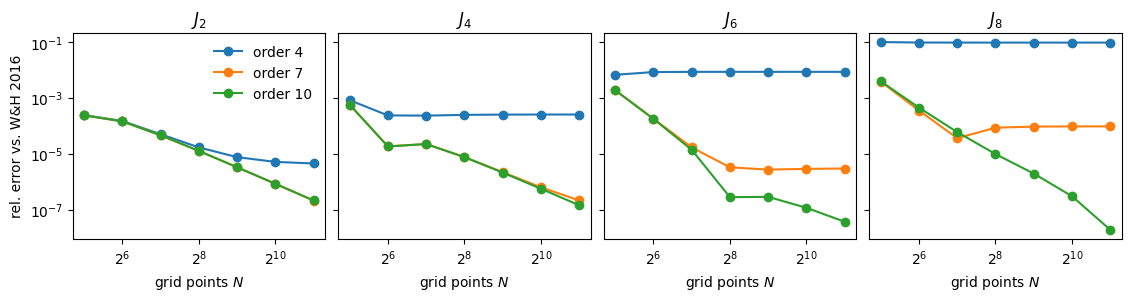

In [8]:
from tutorial_utils import jupiter

Ns = [2**k for k in range(5, 12)]
orders = [4, 7, 10]

fig, axs = plt.subplots(1, 4, figsize=(11.2, 2.9), layout="constrained", sharey=True)
for order in orders:
    errors = np.array([[abs(jupiter(N, order).Js[n] / Bessel[n] - 1) for n in range(1, 5)] for N in Ns])
    for n, ax in enumerate(axs):
        ax.plot(Ns, errors[:, n], "o-", label=f"order {order}")
for n, ax in enumerate(axs, start=1):
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("grid points $N$")
    ax.set_title(f"$J_{{{2 * n}}}$")
axs[0].set_ylabel("rel. error vs. W&H 2016")
axs[0].legend(frameon=False);

Every order has an error floor for each moment, which is reached when the grid is fine enough. Below the floor the error is set by the grid and falls with $N$ in the same way for all orders. **More grid points do not help once the order limits the accuracy, and a higher order does not help while the grid limits it.** A good procedure is hence to choose the lowest order whose floor is below the accuracy you need for the highest moment you care about, then increase $N$ until the result stops changing. Notebook 5 quantifies this together with the run time.

## Error estimates

From a large grid study (the notebooks in the folder `accuracy/`) PyToF keeps tables of the relative error of every $J_{2n}$ as a function of order, $N$, number of bins and integration rule. `get_Js_errors()` looks up the entry for the current settings and stores it in `X.Js_errors` (same indexing as `X.Js`) for convenience, so error estimates are always readily available:

In [9]:
X = jupiter(N=1024, order=10)
X.get_Js_errors()

for n in range(1, 5):
    print(f"{'J_' + str(2 * n):4s}{X.Js[n]: .6e} +/- {X.Js_errors[n]:.1e}   (W&H 2016: {Bessel[n]: .6e})")

J_2  1.398850e-02 +/- 1.2e-08   (W&H 2016:  1.398851e-02)
J_4 -5.318278e-04 +/- 3.0e-10   (W&H 2016: -5.318281e-04)
J_6  3.011832e-05 +/- 3.5e-12   (W&H 2016:  3.011832e-05)
J_8 -2.132116e-06 +/- 6.4e-13   (W&H 2016: -2.132116e-06)


These errors are numerical errors of the Theory of Figures for a polytrope like this one and say nothing about how well a model describes a real planet. They are only available for solid-body rotation and an equidistant grid. With differential rotation, `get_Js_errors()` warns and returns nothing useful: the accuracy there is currently unknown.

## Takeaways

* `ToF(**options)` → `set_barotrope(f)` → `relax_to_barotrope()` → read `X.Js`.
* Convergence is controlled by three relative tolerances and an iteration limit; `reset()` starts over.
* Accuracy has two independent limits, the grid (`N`) and the order; `get_Js_errors()` estimates the combined error.

Next: [2 · plotting](02_plotting.ipynb).